In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import nltk

In [2]:
df = pd.read_csv("spam.csv", encoding="latin1")
df.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
3782,ham,Can you do online transaction?,NaN,NaN,NaN
4406,ham,"Awesome, plan to get here any time after like ...",NaN,NaN,NaN
4575,spam,Congratulations ur awarded 500 of CD vouchers ...,NaN,NaN,NaN
700,ham,How much r Ì_ willing to pay?,NaN,NaN,NaN
4070,ham,I've reached home n i bathe liao... U can call...,NaN,NaN,NaN


In [3]:
df.drop(columns = ["Unnamed: 2","Unnamed: 3","Unnamed: 4"],inplace = True)
df.rename(columns = {"v1":"target","v2":"text"},inplace = True)

In [4]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [5]:
df["target"]  = encoder.fit_transform(df["target"])

In [6]:
df = df.drop_duplicates(keep = "first")

<Axes: >

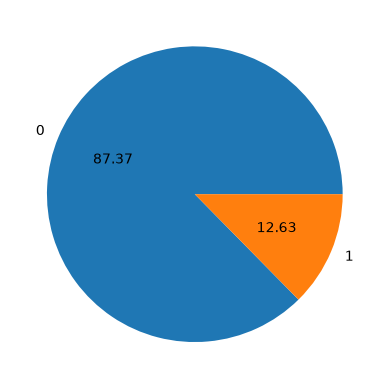

In [7]:
df["target"].value_counts().plot(kind = "pie",autopct = "%0.2f")


In [8]:
nltk.download("punkt")

[nltk_data] Downloading package punkt to C:\Users\ANGEL
[nltk_data]     COMPUTERS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [9]:
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt_tab to C:\Users\ANGEL
[nltk_data]     COMPUTERS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [109]:
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to C:\Users\ANGEL
[nltk_data]     COMPUTERS\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [10]:
df["num_char"] = df["text"].apply(len)
df["num_word"] = df["text"].apply(lambda x:len(nltk.word_tokenize(x)))
df["num_sent"] = df["text"].apply(lambda x:len(nltk.sent_tokenize(x)))

In [39]:
df.describe()

,target,num_char,num_word,num_sent
count,5169.000000,5169.000000,5169.000000,5169.000000
mean,0.126330,78.977945,18.460437,1.965564
std,0.332253,58.236293,13.334441,1.448541
min,0.000000,2.000000,1.000000,1.000000
25%,0.000000,36.000000,9.000000,1.000000
50%,0.000000,60.000000,15.000000,1.000000
75%,0.000000,117.000000,26.000000,2.000000
max,1.000000,910.000000,220.000000,38.000000


In [42]:
df[df["target"] == 0][["num_char","num_word","num_sent"]].describe()

,num_char,num_word,num_sent
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.128432,1.820195
std,56.358207,13.504730,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [48]:
df[df["target"] == 1][["num_char","num_word","num_sent"]].describe()

,num_char,num_word,num_sent
count,653.000000,653.000000,653.000000
mean,137.891271,27.672282,2.970904
std,30.137753,7.010932,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


<Axes: ylabel='Frequency'>

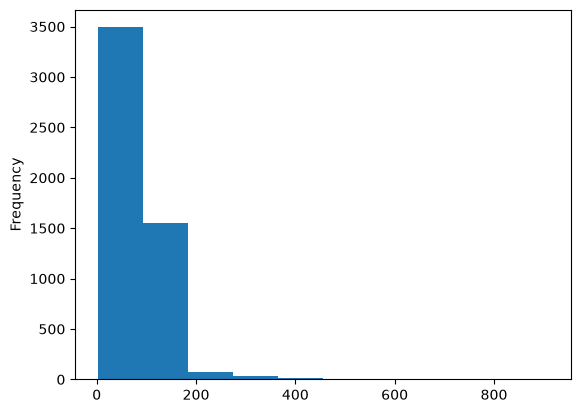

In [24]:
df["num_char"].plot(kind = "hist")

<Axes: ylabel='Frequency'>

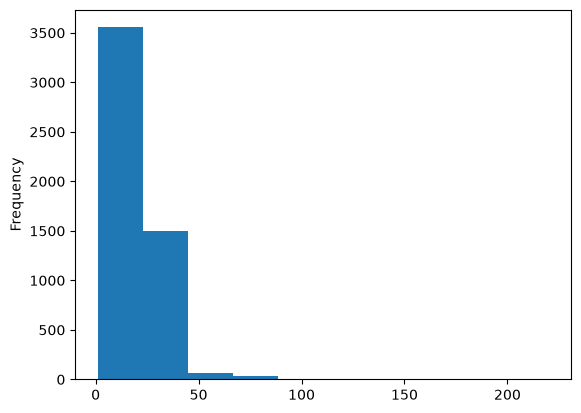

In [27]:
df["num_word"].plot(kind = "hist")

<Axes: ylabel='Frequency'>

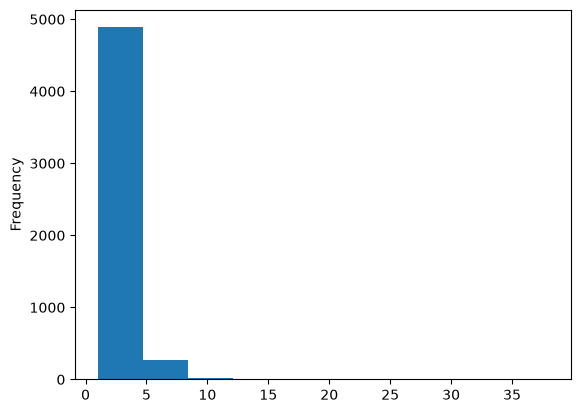

In [26]:
df["num_sent"].plot(kind = "hist")

<Axes: xlabel='num_char', ylabel='Density'>

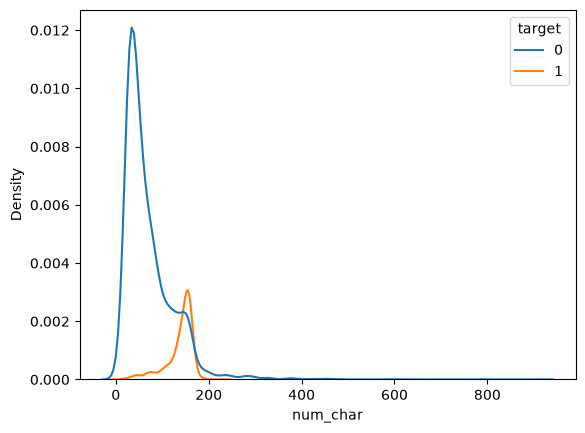

In [19]:
sns.kdeplot(data = df,x = df["num_char"],hue = df["target"])

<Axes: xlabel='num_word', ylabel='Density'>

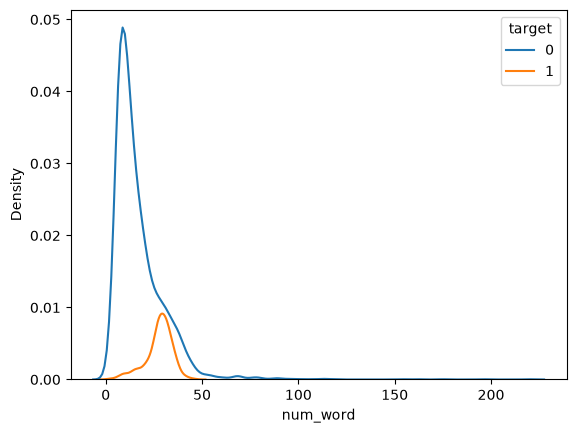

In [21]:
sns.kdeplot(data = df,x = df["num_word"],hue = df["target"])

<Axes: xlabel='num_sent', ylabel='Density'>

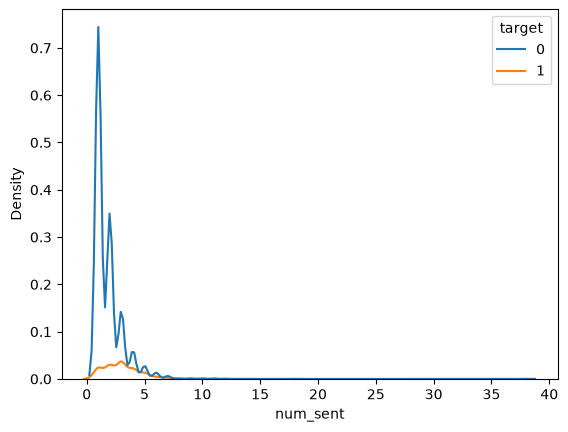

In [20]:
sns.kdeplot(data = df,x = df["num_sent"],hue = df["target"])

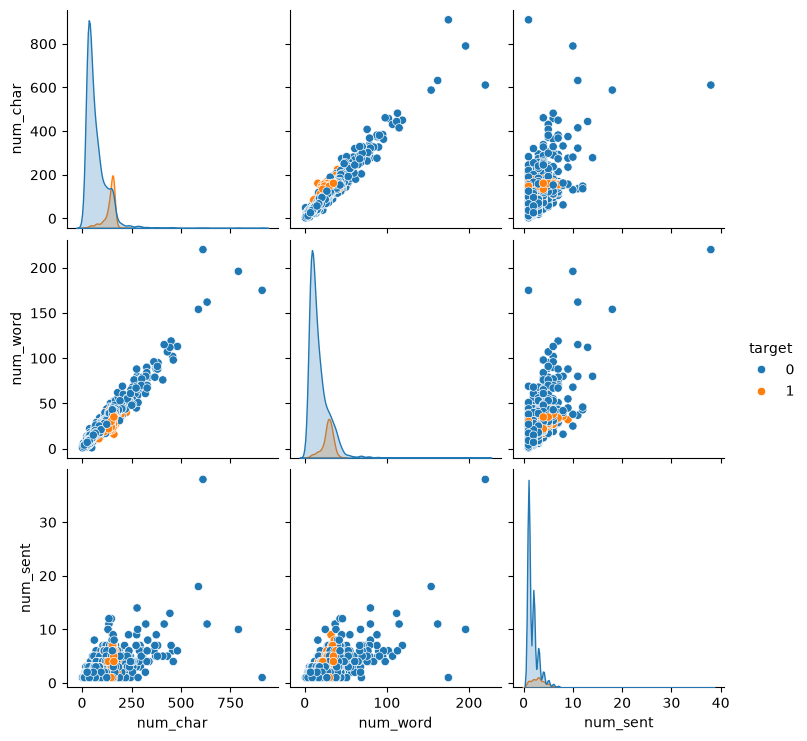

In [49]:
sns.pairplot(df,hue ="target")

<Axes: >

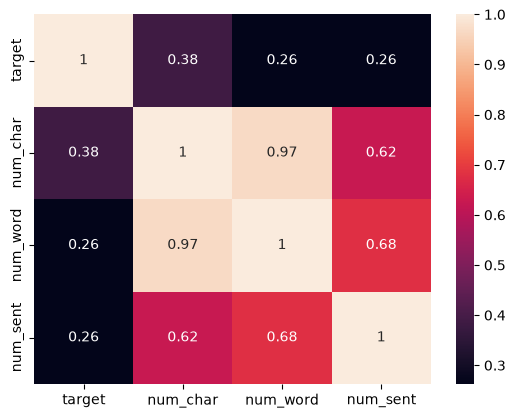

In [58]:
sns.heatmap(df[["target","num_char","num_word","num_sent"]].corr(),annot = True)

In [132]:
from nltk.corpus import stopwords
import string
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()

In [127]:
def transform_text(text):
    text = text.lower()
    text = nltk.word_tokenize(text)
    y = []
    for i in text:
        if i.isalnum():
            y.append(i)
    text = y[:]
    y.clear()

    for i in text:
        if i not in stopwords.words("english") and i not in string.punctuation:
            y.append(i)
        
    text = y[:]
    y.clear()

    for i in text:
      y.append(ps.stem(i))
           
    return " ".join(y)

In [135]:
df["transformed_text"] = df["text"].apply(transform_text)

In [138]:
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer()

In [141]:
x = cv.fit_transform(df["transformed_text"]).toarray()
y = df["target"]

In [144]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,
                                                 y,
                                                 test_size = 0.3,
                                                 random_state = 42
                                                )

In [160]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
tree = DecisionTreeClassifier()
tree.fit(x_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [161]:
y_pred = tree.predict(x_test)

In [186]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.9600257898130239

In [188]:
from sklearn.metrics import classification_report
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.97      0.98      0.98      1331
           1       0.88      0.83      0.86       220

    accuracy                           0.96      1551
   macro avg       0.93      0.91      0.92      1551
weighted avg       0.96      0.96      0.96      1551



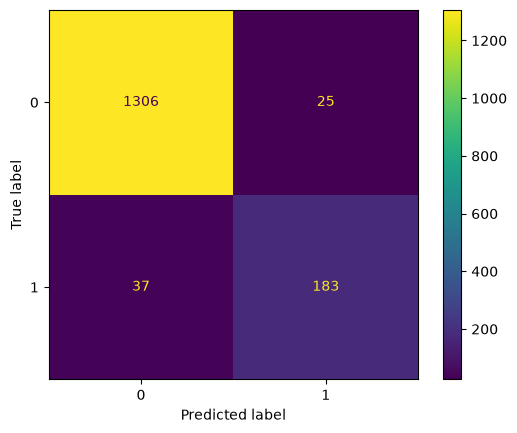

In [182]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_predictions(y_test,y_pred)